<a href="https://colab.research.google.com/github/ek182238/CSC349/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1

Print dataset dimensions, feature summary statistics, and missing value checks. Standardize all 13 features and display a comparison of feature distributions before and after scaling.

Explanation: I split the datset into X (features) and y (target variable). I standardized all 13 features using StandardScaler(). I plotted the unscaled data next to the scaled data,and the feature distributions are much cleaner and more proportional in the scaled values plot.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: fl

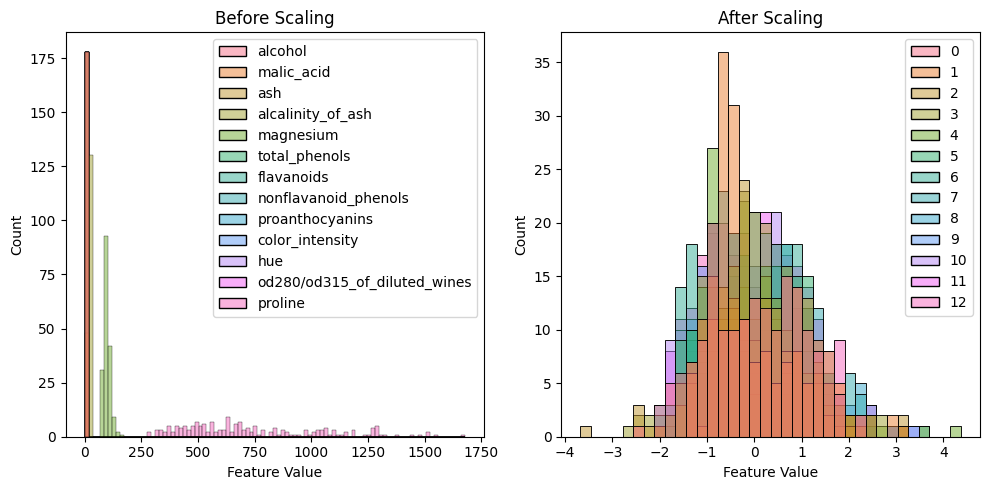

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print(X.info())
print(X.describe())
print(X.isna().sum())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].set_title('Before Scaling')
sns.histplot(X, ax=ax[0])
ax[0].set_xlabel('Feature Value')

ax[1].set_title('After Scaling')
sns.histplot(X_scaled, ax=ax[1])
ax[1].set_xlabel('Feature Value')

plt.tight_layout()
plt.show()

# Task 2

Iterate k from 1 to 10 for K-Means clustering on the scaled features. Compute and plot side-by-side:

1. The **Elbow Method** curve.

2. The **Silhouette Scores** curve for k in [2, 10]. **Print the optimal k value suggested by both metrics**.

Explanation: I created empty arrays for the inertia values (to use for the elbow method curve) and silhouette scores. I iterated through k values 1 to 10, and used that value for n_clusters in each KMeans algorithm. I plotted the elbow method curve and silhouette scores side-by-side.

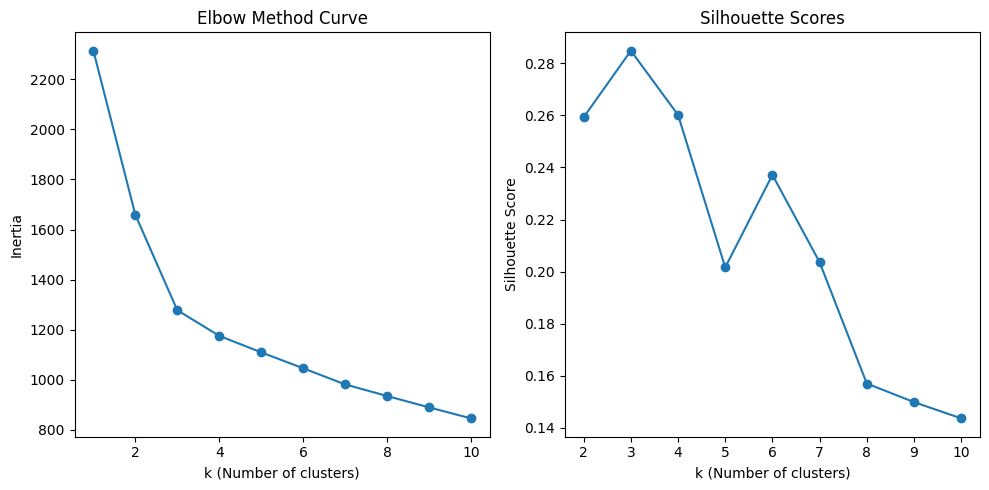

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_scores = []

# Inertia
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_pred = kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# Silhouette scores
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].plot(range(1, 11), inertia_values, marker='o')
ax[0].set_xlabel('k (Number of clusters)')
ax[0].set_ylabel('Inertia')
ax[0].set_title('Elbow Method Curve')

ax[1].plot(range(2, 11), silhouette_scores, marker='o')
ax[1].set_xlabel('k (Number of clusters)')
ax[1].set_ylabel('Silhouette Score')
ax[1].set_title('Silhouette Scores')

plt.tight_layout()
plt.show()

# Task 3

Apply PCA strictly to reduce the 13 scaled features down to 2 principal components for visualization purposes. Fit a K-Means model (k=3) on the 2D projected space. Plot the decision boundaries using the **Voronoi** method.

Explanation: I fit and transformed the scaled X data to PCA with 2 principal components. I used the Voronoi method, based on the code from the customer segmentation example. I used plt.contourf to plot the decision boundaries. Then I plotted the 3 clusters and marked the centroids with an X.

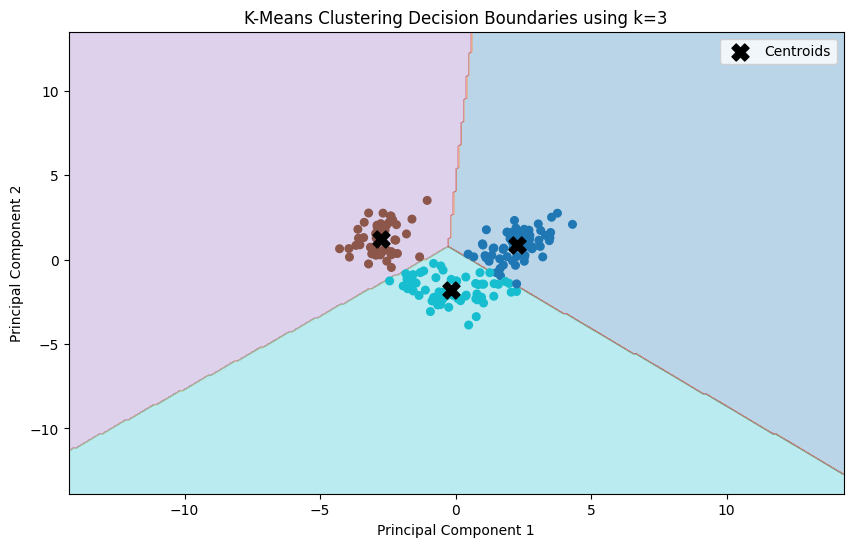

In [19]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

kmeans2 = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans2_labels = kmeans2.fit_predict(X_pca)

# Voronoi method
x_min, x_max = X_pca[:, 0].min() - 10, X_pca[:, 0].max() + 10
y_min, y_max = X_pca[:, 1].min() - 10, X_pca[:, 1].max() + 10
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = kmeans2.predict(grid_points)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='tab10')

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans2_labels,
    cmap='tab10',
    s=30
)
plt.scatter(
    kmeans2.cluster_centers_[:, 0],
    kmeans2.cluster_centers_[:, 1],
    marker='X',
    s=150,
    color='black',
    label='Centroids'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clustering Decision Boundaries using k=3')
plt.legend()
plt.show()

# Task 4

Select 5 representative wine samples from the dataset. Using the fitted 13-feature K-Means model (k=3), compute the distance matrix. Generate and display a heatmap visualizing the soft clustering distance profiles across all 3 cluster centroids, highlighting the minimum distance corresponding to each sample's hard cluster assignment.

Explanation: I fitted a kmeans model for 13 features. I selected 5 samples and computed a distance matrix using those 5 scaled samples. I plotted a heatmap of the distance of each sample wine from the 3 centroids. The one they have the closest distance to is the one they are assigned to.

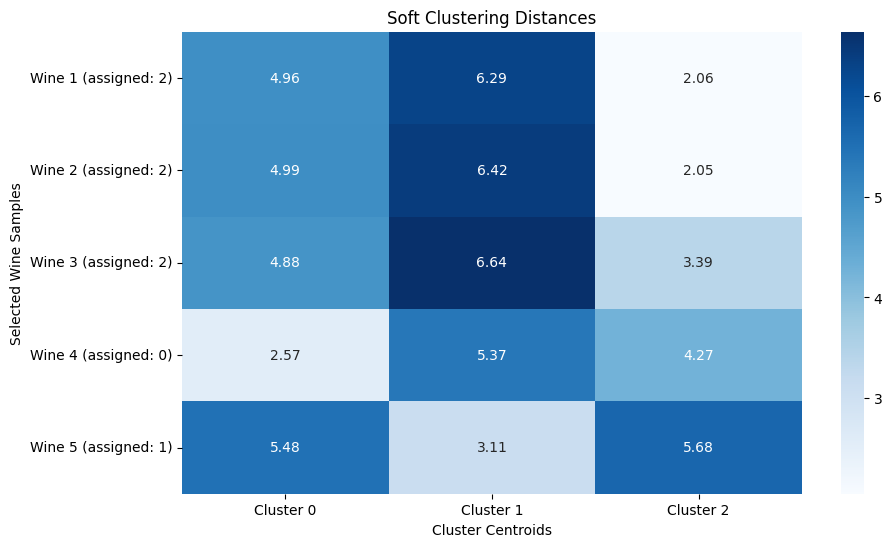

In [20]:
kmeans13 = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans13_labels = kmeans13.fit_predict(X_scaled)

sample_indices = [0, 10, 50, 100, 150]
X_samples = X_scaled[sample_indices]
distance_matrix = kmeans13.transform(X_samples)
new_predictions = kmeans13.predict(X_samples)

plt.figure(figsize=(10, 6))
sns.heatmap(
    distance_matrix,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    xticklabels=[f'Cluster {i}' for i in range(3)],
    yticklabels=[f'Wine {i+1} (assigned: {pred})' for i, pred in enumerate(new_predictions)]
)
plt.title('Soft Clustering Distances')
plt.xlabel('Cluster Centroids')
plt.ylabel('Selected Wine Samples')
plt.show()

# Task 5

Fit a `DBSCAN` model on the 13-dimensional scaled feature space. Experiment with the two needed hyperparameter settings. Print the number of identified clusters and noise points. Visualize the DBSCAN assignments on the 2D PCA projection space, clearly distinguishing noise points from core cluster members.

Explanation: I tested different epsilon values and min_samples values and printed the result of each DBSCAN model using each combination of hyperparameters. The hyperparameters I chose were 2.4 epsilon and 4 min_samples. I made a scatterplot that displayed the 2 clusters, and I marked the noise (-1) points with X. None of the models with 3 (or more) clusters did the correct cluster for the third one, so I went with the one that only found 2 clusters.

Epsilon: 1.5, Min Samples: 3	 Clusters: 8	Noise points: 147
Epsilon: 1.5, Min Samples: 4	 Clusters: 2	Noise points: 169
Epsilon: 1.5, Min Samples: 5	 Clusters: 0	Noise points: 178
Epsilon: 1.5, Min Samples: 6	 Clusters: 0	Noise points: 178
Epsilon: 1.5, Min Samples: 7	 Clusters: 0	Noise points: 178
Epsilon: 2.0, Min Samples: 3	 Clusters: 5	Noise points: 64
Epsilon: 2.0, Min Samples: 4	 Clusters: 6	Noise points: 66
Epsilon: 2.0, Min Samples: 5	 Clusters: 5	Noise points: 85
Epsilon: 2.0, Min Samples: 6	 Clusters: 3	Noise points: 100
Epsilon: 2.0, Min Samples: 7	 Clusters: 3	Noise points: 110
Epsilon: 2.1, Min Samples: 3	 Clusters: 4	Noise points: 52
Epsilon: 2.1, Min Samples: 4	 Clusters: 3	Noise points: 57
Epsilon: 2.1, Min Samples: 5	 Clusters: 3	Noise points: 62
Epsilon: 2.1, Min Samples: 6	 Clusters: 3	Noise points: 70
Epsilon: 2.1, Min Samples: 7	 Clusters: 3	Noise points: 77
Epsilon: 2.2, Min Samples: 3	 Clusters: 3	Noise points: 44
Epsilon: 2.2, Min Samples: 4	 Clusters: 2	Noise p

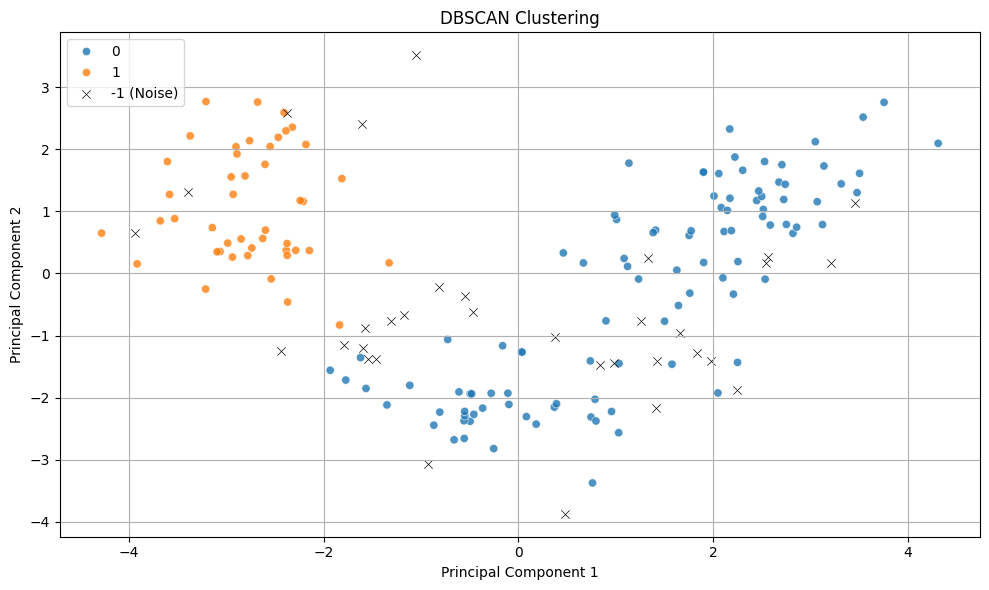

In [21]:
from sklearn.cluster import DBSCAN

eps_values = [1.5, 2.0, 2.1, 2.2, 2.3, 2.5]
min_samples_values = [3, 4, 5, 6, 7]

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        dbscan_labels = dbscan.fit_predict(X_scaled)

        n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
        n_noise = list(dbscan_labels).count(-1)

        print(f'Epsilon: {eps}, Min Samples: {min_samples}\t Clusters: {n_clusters}\tNoise points: {n_noise}')

dbscan = DBSCAN(eps=2.4, min_samples=4)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)
print('\nDBSCAN model:')
print(f'Clusters: {n_clusters}\nNoise points: {n_noise}')

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[dbscan_labels != -1, 0],
    y=X_pca[dbscan_labels != -1, 1],
    hue=dbscan_labels[dbscan_labels != -1],
    palette='tab10',
    legend='full',
    alpha=0.8
)
sns.scatterplot(
    x=X_pca[dbscan_labels == -1, 0],
    y=X_pca[dbscan_labels == -1, 1],
    color='black',
    marker='x',
    label='-1 (Noise)'
)

plt.title('DBSCAN Clustering')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Task 6

Fit an `HDBSCAN` model (using `min_cluster_size=5` or `min_samples=5`) on the 13-dimensional scaled feature space. Print the total number of clusters discovered and noise points detected. Visualize the resulting HDBSCAN cluster assignments on the 2D PCA projection space.

Explanation: I implemented the HDBSCAN model and plotted the resulting clusters and noise points the same way as I did with the DBSCAN model in task 5. The difference in this task is that I used min_cluster_size=5. A problem I ran into is that even though the number of clusters discovered was 3, the plot only displays 2 clusters.

Clusters: 3
Noise points: 58


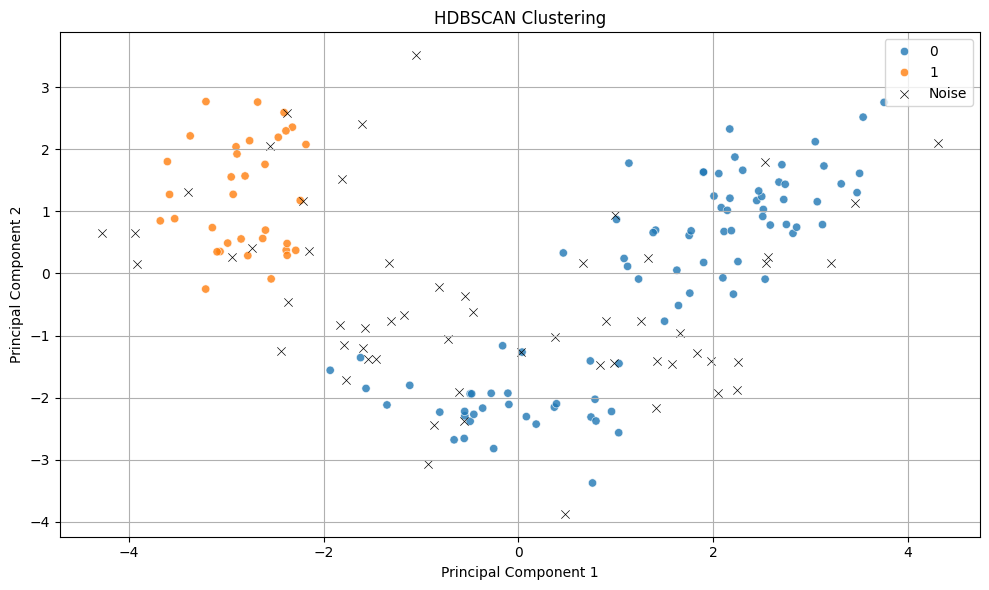

In [22]:
from sklearn.cluster import HDBSCAN

hdbscan = HDBSCAN(min_cluster_size=5)
hdbscan_labels = hdbscan.fit_predict(X_scaled)

n_clusters_hdb = len(set(hdbscan_labels))
n_noise_hdb = list(hdbscan_labels).count(-1)

print(f'Clusters: {n_clusters_hdb}')
print(f'Noise points: {n_noise_hdb}')

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[hdbscan_labels != -1, 0],
    y=X_pca[hdbscan_labels != -1, 1],
    hue=hdbscan_labels[hdbscan_labels != -1],
    palette='tab10',
    legend='full',
    alpha=0.8
)
sns.scatterplot(
    x=X_pca[hdbscan_labels == -1, 0],
    y=X_pca[hdbscan_labels == -1, 1],
    color='black',
    marker='x',
    label='Noise'
)

plt.title('HDBSCAN Clustering')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Task 7

Compute a single-linkage hierarchical clustering matrix on the scaled Wine features. Plot a hierarchical clustering **dendrogram** to visualize how individual chemical profiles merge across distance thresholds, connecting the visual structure to HDBSCAN's stability extraction mechanics.

Explanation: I made a linkage matrix (single linkage on the X_scaled data), and then I used it to plot a hierarchical clustering dendrogram.

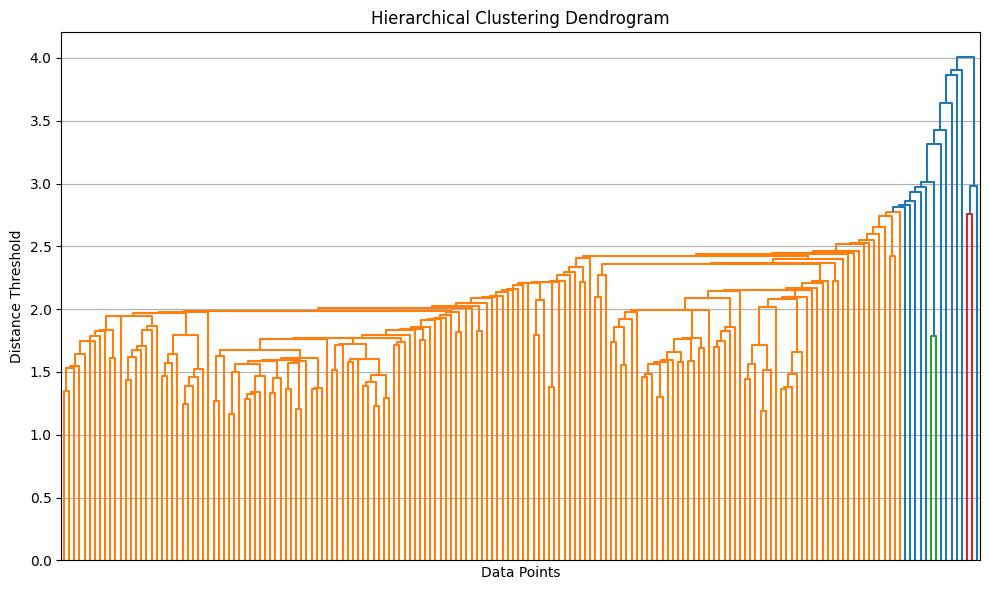

In [38]:
from scipy.cluster.hierarchy import dendrogram, linkage

linkage_matrix = linkage(X_scaled, method='single')

plt.figure(figsize=(10, 6))
dendrogram(linkage_matrix,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=True,
           no_labels=True)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Distance Threshold')
plt.grid(True)
plt.tight_layout()
plt.show()

# Task 8

Treat the cluster assignments generated by **K-Means (k=3), DBSCAN, and HDBSCAN** as categorical feature representations or pseudo-labels. Perform a stratified train/test split (80/20) on the Wine dataset and conduct an experiment: train a supervised classifier such as a **Random Forest** or **Logistic Regression** using these cluster labels to predict the actual ground-truth wine cultivars (Class 0, 1, 2). **Plot** the **classification accuracy and Silhouette Scores for all three algorithms**.

Explanation: I added the labels into a dictionary, catrgorizing them by the type of algorithm. I made empty dictionaries for accuracies and silhouette scores. I iterated through all the labels, trained them in an 80% 20% split, and trained a random forest classifier with 100 estimators on the values. The accuracy and silhouette scores were saved and printed. I plotted the accuracy score and silhouette score bar graphs side by side. Kmeans ended up having the highest scores.

Kmeans Accuracy: 0.9722 Silhouette Score: 0.2849
DBSCAN Accuracy: 0.7500 Silhouette Score: 0.2048
HDBSCAN Accuracy: 0.7500 Silhouette Score: 0.1381


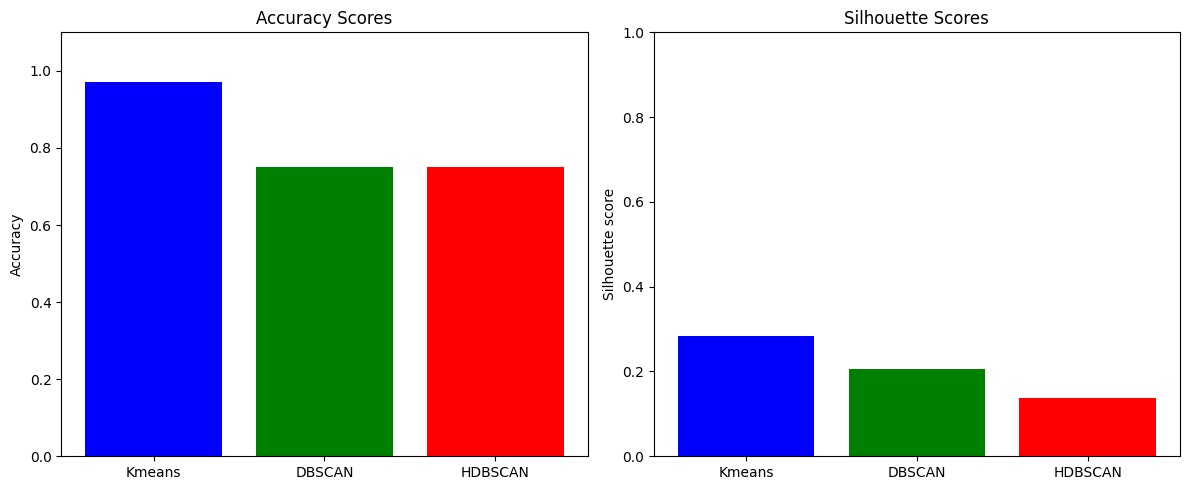

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, silhouette_score
import matplotlib.pyplot as plt
import numpy as np

clustering_labels = {
    'Kmeans': kmeans13_labels,
    'DBSCAN': dbscan_labels,
    'HDBSCAN': hdbscan_labels
}

accuracies = {}
silhouette_scores = {}

for name, labels in clustering_labels.items():
    X_cluster = np.array(labels).reshape(-1, 1)
    X_train, X_test, y_train, y_test = train_test_split(
        X_cluster,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_clf.fit(X_train, y_train)
    y_pred_rf = rf_clf.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred_rf)
    accuracies[name] = accuracy

    unique_labels = len(set(labels)) - (1 if -1 in labels else 0)
    if unique_labels > 1:
        score = silhouette_score(X_scaled, labels)
    else:
        score = 0.0

    silhouette_scores[name] = score
    print(f'{name} Accuracy: {accuracy:.4f} Silhouette Score: {score:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy plot
ax[0].bar(accuracies.keys(), accuracies.values(), color=['blue', 'green', 'red'])
ax[0].set_title('Accuracy Scores')
ax[0].set_ylabel('Accuracy')
ax[0].set_ylim(0, 1.1)

# Silhouette score plot
ax[1].bar(silhouette_scores.keys(), silhouette_scores.values(), color=['blue', 'green', 'red'])
ax[1].set_title('Silhouette Scores')
ax[1].set_ylabel('Silhouette score')
ax[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()